# Intelligent Steel Surface Fault Detection (Kelompok 16)

**TE2514031 Kecerdasan Buatan, ITK, Gasal 2026/2027**
Anggota: Syahmi, Marsa Naufal, Muhammad Irvan Hannif, Muhammad Ramdi Pratama

Sistem hybrid: **GA** memilih fitur → **PSO** mencari hyperparameter → **MLP** memprediksi 7 jenis cacat → **Fuzzy Mamdani** menerjemahkan prediksi menjadi keputusan inspeksi (Accept / Monitor / Rework / Reject).

Notebook ini menjalankan eksperimen yang sama dengan `train.py`, tetapi tahap demi tahap supaya hasil tiap algoritma bisa dilihat langsung. Semua mekanisme inti (GA, PSO, MLP, Fuzzy) ada di folder `src/` dan ditulis manual dengan NumPy. Di akhir notebook, artefak disimpan ke `artifacts/` dengan format yang sama seperti `train.py`, jadi dashboard (`streamlit run app.py`) dan `generate_report.py` bisa langsung membaca hasilnya.

| Model | Komponen |
|---|---|
| A | Baseline MLP, semua fitur, hyperparameter default |
| B | GA + MLP |
| C | PSO + MLP (semua fitur) |
| D | GA + PSO + MLP |
| E | D + Fuzzy (sistem final dashboard) |

In [1]:
import json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src import config as C
from src.data import load_dataset, three_way_split
from src import pipeline as P
from src import fuzzy as FZ

JOBS = -1          # independent run GA/PSO dijalankan paralel di semua core CPU
pd.set_option("display.width", 160)
plt.rcParams["figure.dpi"] = 110
t0 = time.time()
print("Seed split:", C.SEED, "| GA:", C.GA, "\nPSO:", C.PSO, "| runs:", C.N_RUNS, "| seed final:", C.N_FINAL_SEEDS)

Seed split: 42 | GA: {'pop_size': 20, 'generations': 15, 'crossover_rate': 0.8, 'mutation_rate': 0.03, 'tournament_k': 3, 'elitism': 2, 'penalty': 0.02} 
PSO: {'n_particles': 10, 'iterations': 12, 'w': 0.7, 'c1': 1.5, 'c2': 1.5} | runs: 5 | seed final: 5


## 1. Dataset

UCI Steel Plates Faults (ID 198): setiap baris adalah satu cacat pada pelat baja, dijelaskan oleh 27 fitur geometri dan luminositas. Labelnya 7 kolom biner (one-hot) yang diubah menjadi satu kelas dengan `argmax`. `load_dataset()` membaca `data/steel_plates.csv`; kalau file itu belum ada, fungsi ini mengunduh dari UCI lewat `ucimlrepo`.

In [2]:
X, y = load_dataset()
df = X.copy()
df["Class"] = [C.CLASSES[i] for i in y]
print("Ukuran:", X.shape, "| missing value:", int(X.isna().sum().sum()), "| baris duplikat:", int(X.duplicated().sum()))
df.head(20)

Ukuran: (1941, 27) | missing value: 0 | baris duplikat: 0


,X_Minimum,X_Maximum,Y_Minimum,Y_Maximum,Pixels_Areas,X_Perimeter,Y_Perimeter,Sum_of_Luminosity,Minimum_of_Luminosity,Maximum_of_Luminosity,...,Edges_X_Index,Edges_Y_Index,Outside_Global_Index,LogOfAreas,Log_X_Index,Log_Y_Index,Orientation_Index,Luminosity_Index,SigmoidOfAreas,Class
0,42,50,270900,270944,267,17,44,24220,76,108,...,0.4706,1.0000,1.0,2.4265,0.9031,1.6435,0.8182,-0.2913,0.5822,Pastry
1,645,651,2538079,2538108,108,10,30,11397,84,123,...,0.6000,0.9667,1.0,2.0334,0.7782,1.4624,0.7931,-0.1756,0.2984,Pastry
2,829,835,1553913,1553931,71,8,19,7972,99,125,...,0.7500,0.9474,1.0,1.8513,0.7782,1.2553,0.6667,-0.1228,0.2150,Pastry
3,853,860,369370,369415,176,13,45,18996,99,126,...,0.5385,1.0000,1.0,2.2455,0.8451,1.6532,0.8444,-0.1568,0.5212,Pastry
4,1289,1306,498078,498335,2409,60,260,246930,37,126,...,0.2833,0.9885,1.0,3.3818,1.2305,2.4099,0.9338,-0.1992,1.0000,Pastry
5,430,441,100250,100337,630,20,87,62357,64,127,...,0.5500,1.0000,1.0,2.7993,1.0414,1.9395,0.8736,-0.2267,0.9874,Pastry
6,413,446,138468,138883,9052,230,432,1481991,23,199,...,0.1435,0.9607,1.0,3.9567,1.5185,2.6181,0.9205,0.2791,1.0000,Pastry
7,190,200,210936,210956,132,11,20,20007,124,172,...,0.9091,1.0000,1.0,2.1206,1.0000,1.3010,0.5000,0.1841,0.3359,Pastry
8,330,343,429227,429253,264,15,26,29748,53,148,...,0.8667,1.0000,1.0,2.4216,1.1139,1.4150,0.5000,-0.1197,0.5593,Pastry
9,74,90,779144,779308,1506,46,167,180215,53,143,...,0.3478,0.9820,1.0,3.1778,1.2041,2.2148,0.9024,-0.0651,1.0000,Pastry


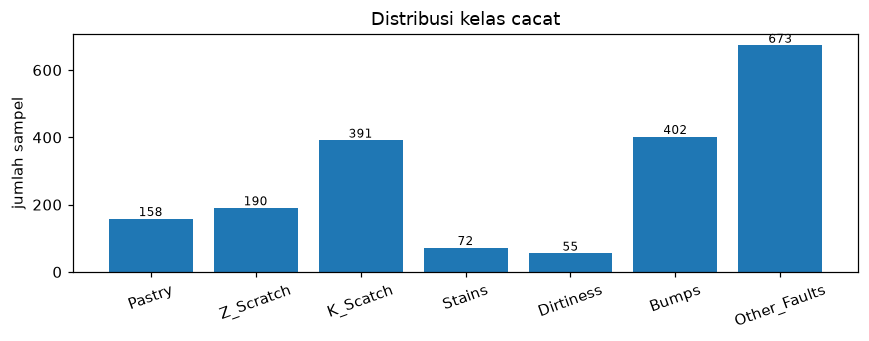

{'Pastry': 0.081, 'Z_Scratch': 0.098, 'K_Scatch': 0.201, 'Stains': 0.037, 'Dirtiness': 0.028, 'Bumps': 0.207, 'Other_Faults': 0.347}


In [3]:
counts = df["Class"].value_counts().reindex(C.CLASSES)
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.bar(counts.index, counts.values, color="#1f77b4")
for i, v in enumerate(counts.values):
    ax.text(i, v + 8, str(v), ha="center", fontsize=8)
ax.set_title("Distribusi kelas cacat"); ax.set_ylabel("jumlah sampel"); plt.xticks(rotation=20)
plt.tight_layout(); plt.show()
print((counts / counts.sum()).round(3).to_dict())

Kelasnya tidak seimbang: Other_Faults sekitar 35% data, sedangkan Dirtiness kurang dari 3%. Model yang selalu menebak Other_Faults sudah benar sepertiga waktu, jadi accuracy saja menyesatkan. Karena itu fitness GA/PSO dan evaluasi akhir memakai **F1-macro** (rata-rata F1 per kelas dengan bobot sama), dan MLP dilatih dengan **class weight**.

In [4]:
X.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
X_Minimum,1941.0,571.136,520.691,0.000,51.000,435.000,1053.000,1.705000e+03
X_Maximum,1941.0,617.964,497.627,4.000,192.000,467.000,1072.000,1.713000e+03
Y_Minimum,1941.0,1650684.868,1774578.415,6712.000,471253.000,1204128.000,2183073.000,1.298766e+07
Y_Maximum,1941.0,1650738.705,1774590.089,6724.000,471281.000,1204136.000,2183084.000,1.298769e+07
Pixels_Areas,1941.0,1893.878,5168.460,2.000,84.000,174.000,822.000,1.526550e+05
X_Perimeter,1941.0,111.855,301.209,2.000,15.000,26.000,84.000,1.044900e+04
Y_Perimeter,1941.0,82.966,426.483,1.000,13.000,25.000,83.000,1.815200e+04
Sum_of_Luminosity,1941.0,206312.148,512293.588,250.000,9522.000,19202.000,83011.000,1.159141e+07
Minimum_of_Luminosity,1941.0,84.549,32.134,0.000,63.000,90.000,106.000,2.030000e+02
Maximum_of_Luminosity,1941.0,130.194,18.691,37.000,124.000,127.000,140.000,2.530000e+02


## 2. Split data tanpa kebocoran

Data dibagi stratified 60/20/20: **sub-train** untuk melatih MLP, **validation** untuk fitness GA/PSO dan early stopping, **test** hanya untuk evaluasi akhir. Scaler di-fit hanya pada sub-train di dalam setiap evaluasi.

In [5]:
S = three_way_split(X, y)
all_cols = list(X.columns)
for k in ["sub", "val", "te"]:
    print(f"{k:>3}: {len(S['y_' + k]):4d} sampel | per kelas {np.bincount(S['y_' + k]).tolist()}")

sub: 1164 sampel | per kelas [95, 114, 235, 43, 33, 241, 403]
val:  388 sampel | per kelas [31, 38, 78, 15, 11, 80, 135]
 te:  389 sampel | per kelas [32, 38, 78, 14, 11, 81, 135]


## 3. Genetic Algorithm: seleksi fitur

- **Kromosom:** vektor biner sepanjang 27; gen bernilai 1 berarti fitur dipakai.
- **Fitness:** F1-macro validation dari MLP (hyperparameter default) dikurangi penalti `0.02 × (fitur terpilih / 27)`, supaya subset yang lebih ringkas diutamakan bila performanya setara.
- **Operator:** seleksi turnamen (k = 3), uniform crossover (0.8), bit-flip mutation (0.03), elitisme 2. Kromosom kosong diperbaiki dengan menyalakan satu gen acak.
- GA dijalankan **5 kali independen** (seed berbeda) untuk melihat kestabilannya.

In [6]:
t = time.time()
ga_runs = P.run_ga_multi(S, all_cols, dict(C.GA), C.N_RUNS, JOBS)
ga_best = max(ga_runs, key=lambda r: r["fitness"])
ga_cols = [c for c, k in zip(all_cols, ga_best["chromosome"]) if k]
ga_stats = P.stats(ga_runs)
print(f"Selesai {time.time() - t:.0f} s | fitness best/mean/std = {ga_stats['best']:.4f} / {ga_stats['mean']:.4f} / {ga_stats['std']:.4f}")
print(f"Fitur terpilih ({len(ga_cols)}/{len(all_cols)}):", ga_cols)
pd.DataFrame([{"run": i + 1, "seed": r["seed"], "fitness": r["fitness"], "n_fitur": sum(r["chromosome"]),
               "evaluasi_unik": r["n_evals"]} for i, r in enumerate(ga_runs)]).round(4)

Selesai 84 s | fitness best/mean/std = 0.8024 / 0.7878 / 0.0076
Fitur terpilih (16/27): ['X_Minimum', 'Y_Maximum', 'Pixels_Areas', 'X_Perimeter', 'Sum_of_Luminosity', 'Minimum_of_Luminosity', 'Maximum_of_Luminosity', 'Length_of_Conveyer', 'TypeOfSteel_A300', 'TypeOfSteel_A400', 'Steel_Plate_Thickness', 'Empty_Index', 'Outside_Global_Index', 'Log_X_Index', 'Log_Y_Index', 'Orientation_Index']


,run,seed,fitness,n_fitur,evaluasi_unik
0,1,100,0.8024,16,238
1,2,101,0.7847,17,218
2,3,102,0.7879,19,208
3,4,103,0.7815,20,201
4,5,104,0.7824,20,250


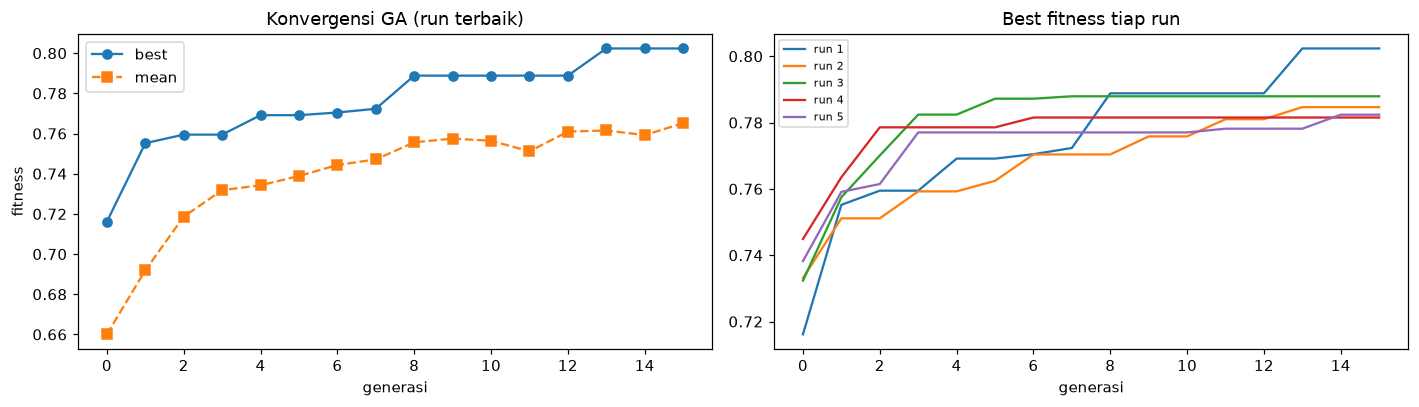

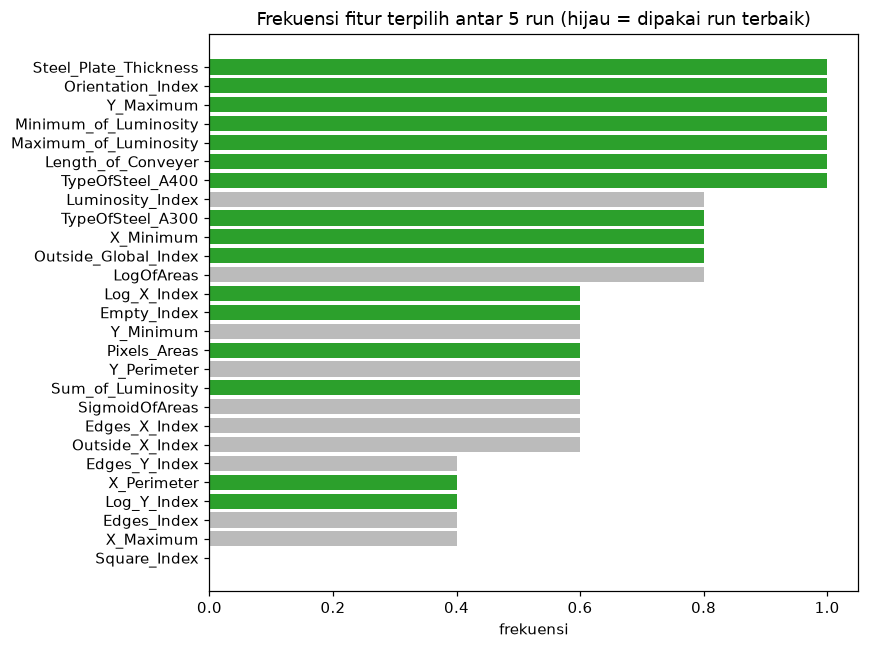

Dieliminasi: ['X_Maximum', 'Y_Minimum', 'Y_Perimeter', 'Edges_Index', 'Square_Index', 'Outside_X_Index', 'Edges_X_Index', 'Edges_Y_Index', 'LogOfAreas', 'Luminosity_Index', 'SigmoidOfAreas']


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].plot(ga_best["hist_best"], "o-", label="best"); axes[0].plot(ga_best["hist_mean"], "s--", label="mean")
axes[0].set_title("Konvergensi GA (run terbaik)"); axes[0].set_xlabel("generasi"); axes[0].set_ylabel("fitness"); axes[0].legend()
for i, r in enumerate(ga_runs):
    axes[1].plot(r["hist_best"], label=f"run {i + 1}")
axes[1].set_title("Best fitness tiap run"); axes[1].set_xlabel("generasi"); axes[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

freq = pd.Series(np.mean([r["chromosome"] for r in ga_runs], axis=0), index=all_cols).sort_values()
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(freq.index, freq.values, color=["#2ca02c" if c in ga_cols else "#bbbbbb" for c in freq.index])
ax.set_title("Frekuensi fitur terpilih antar 5 run (hijau = dipakai run terbaik)"); ax.set_xlabel("frekuensi")
plt.tight_layout(); plt.show()
print("Dieliminasi:", [c for c in all_cols if c not in ga_cols])

**Yang terlihat dari hasil GA**
- Run terbaik (seed 100) memilih **16 dari 27 fitur** dengan fitness validation 0.8024. Lima run menghasilkan fitness 0.782 sampai 0.802 (std 0.0076), dengan jumlah fitur 16 sampai 20. GA tidak selalu sampai ke subset yang sama, jadi seleksinya cukup dipengaruhi seed.
- Fitur yang dibuang antara lain X_Maximum, Y_Minimum, dan LogOfAreas. Fitur-fitur ini punya "kembaran" yang tetap dipakai (X_Minimum, Y_Maximum, Pixels_Areas), sehingga informasinya tidak benar-benar hilang.

## 4. PSO: optimasi hyperparameter MLP

Setiap partikel berisi 4 dimensi kontinu: `log10(learning rate)` ∈ [−4, −1.5], `hidden units` ∈ [8, 128], `dropout` ∈ [0, 0.5], dan `log2(batch size)` ∈ [4, 7]. Posisi kontinu dibulatkan saat dievaluasi (hidden ke bilangan bulat, batch ke 16/32/64/128). Kecepatan dibatasi 20% lebar rentang, dan posisi di-*clip* ke batas.

$$v \leftarrow w v + c_1 r_1 (p_{best} - x) + c_2 r_2 (g_{best} - x), \quad x \leftarrow x + v \qquad (w = 0.7,\ c_1 = c_2 = 1.5)$$

Fitness = F1-macro validation. PSO dijalankan dua kali (masing-masing 5 run independen): pada **semua fitur** untuk Model C, dan pada **fitur hasil GA** untuk Model D.

In [8]:
t = time.time()
pso_all = P.run_pso_multi(S, all_cols, dict(C.PSO), C.N_RUNS, JOBS)
pso_ga = P.run_pso_multi(S, ga_cols, dict(C.PSO), C.N_RUNS, JOBS)
hp_c = max(pso_all, key=lambda r: r["fitness"])["hp"]
hp_d = max(pso_ga, key=lambda r: r["fitness"])["hp"]
print(f"Selesai {time.time() - t:.0f} s")
for nama, runs in [("C (semua fitur)", pso_all), ("D (fitur GA)", pso_ga)]:
    s = P.stats(runs)
    print(f"PSO {nama}: best/mean/std = {s['best']:.4f} / {s['mean']:.4f} / {s['std']:.4f}")
print("HP Model C:", hp_c); print("HP Model D:", hp_d)
pd.DataFrame([{"skenario": nama, "run": i + 1, "fitness": r["fitness"], **r["hp"]}
              for nama, runs in [("C", pso_all), ("D", pso_ga)] for i, r in enumerate(runs)]).round(5)

Selesai 833 s
PSO C (semua fitur): best/mean/std = 0.8085 / 0.7983 / 0.0066
PSO D (fitur GA): best/mean/std = 0.8181 / 0.8092 / 0.0064
HP Model C: {'lr': 0.008370244165091405, 'hidden': 97, 'dropout': 0.02915053610327184, 'batch_size': 128}
HP Model D: {'lr': 0.002308458827801728, 'hidden': 99, 'dropout': 0.026679257875922464, 'batch_size': 16}


,skenario,run,fitness,lr,hidden,dropout,batch_size
0,C,1,0.79627,0.00136,128,0.18352,32
1,C,2,0.80251,0.00595,76,0.09169,32
2,C,3,0.79500,0.00187,63,0.27007,32
3,C,4,0.80854,0.00837,97,0.02915,128
4,C,5,0.78936,0.00388,112,0.11089,128
5,D,1,0.81808,0.00231,99,0.02668,16
6,D,2,0.79859,0.00337,52,0.09215,32
7,D,3,0.81049,0.00476,119,0.09693,64
8,D,4,0.80731,0.00646,128,0.16656,64
9,D,5,0.81170,0.01423,100,0.15797,64


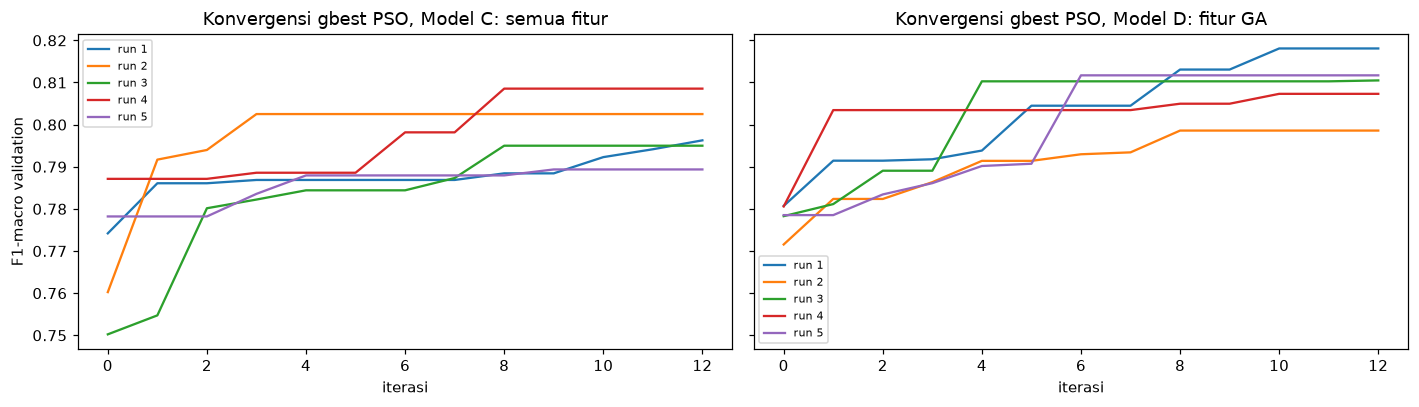

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
for ax, (nama, runs) in zip(axes, [("Model C: semua fitur", pso_all), ("Model D: fitur GA", pso_ga)]):
    for i, r in enumerate(runs):
        ax.plot(r["hist_best"], label=f"run {i + 1}")
    ax.set_title(f"Konvergensi gbest PSO, {nama}"); ax.set_xlabel("iterasi"); ax.legend(fontsize=7)
axes[0].set_ylabel("F1-macro validation")
plt.tight_layout(); plt.show()

**Yang terlihat dari hasil PSO**
- Pada fitur hasil GA (Model D), fitness validation terbaik 0.8181 (mean 0.8092); pada semua fitur (Model C) 0.8085 (mean 0.7983).
- Hyperparameter terbaik kedua skenario sama-sama memakai hidden unit besar (97 dan 99) dengan dropout rendah (sekitar 0.03). Learning rate dan batch size-nya berbeda jauh (C: lr 0.0084, batch 128; D: lr 0.0023, batch 16). Antar-run pun kombinasinya beragam, jadi permukaan fitness-nya cukup datar: banyak kombinasi memberi F1 yang mirip.
- Sebagian besar run masih naik di iterasi terakhir (misalnya run 1 skenario D), tanda 12 iterasi belum sepenuhnya konvergen.

## 5. Evaluasi akhir Model A–D pada test set

Setiap model dilatih ulang dengan **5 seed** (maksimal 200 epoch, early stopping patience 15 pada validation), lalu dievaluasi pada test set. Angka yang dilaporkan adalah mean ± std dari 5 seed. Model terbaik (F1 validation tertinggi) disimpan untuk confusion matrix dan dashboard.

In [10]:
cfgs = {"A: Baseline NN": (all_cols, C.DEFAULT_HP), "B: GA + NN": (ga_cols, C.DEFAULT_HP),
        "C: PSO + NN": (all_cols, hp_c), "D: GA + PSO + NN": (ga_cols, hp_d)}
results, best_models = {}, {}
for name, (cols, hp) in cfgs.items():
    results[name], best_models[name] = P.evaluate_model(S, cols, hp, C.N_FINAL_SEEDS, C.FINAL_EPOCHS, C.PATIENCE)
    m = results[name]["metrics"]
    print(f"{name:18s} | F1-macro {m['f1_macro']['mean']:.4f} ± {m['f1_macro']['std']:.4f} | "
          f"accuracy {m['accuracy']['mean']:.4f} | {results[name]['n_features']} fitur | {results[name]['n_params']} param")

A: Baseline NN     | F1-macro 0.7471 ± 0.0101 | accuracy 0.7352 | 27 fitur | 2183 param


B: GA + NN         | F1-macro 0.7299 ± 0.0138 | accuracy 0.7219 | 16 fitur | 1831 param


C: PSO + NN        | F1-macro 0.7516 ± 0.0119 | accuracy 0.7445 | 27 fitur | 12908 param


D: GA + PSO + NN   | F1-macro 0.7589 ± 0.0042 | accuracy 0.7470 | 16 fitur | 12283 param


## 6. Model E: D + Fuzzy Mamdani

Fuzzy menerima dua input dari probabilitas MLP:
- **severity** (0–10) = rata-rata tingkat keparahan kelas, dibobot probabilitas prediksi. Nilai severity per kelas adalah asumsi kelompok di `src/config.py`.
- **confidence** (0–1) = probabilitas tertinggi.

Output **priority** 0–100 dipetakan ke Accept / Monitor / Rework / Reject. Metodenya AND = min, implikasi = clip, agregasi = max, defuzzifikasi = centroid. Fuzzy tidak mengubah prediksi kelas (akurasi E sama dengan D); fungsinya mengubah probabilitas menjadi keputusan inspeksi yang bisa dijelaskan.

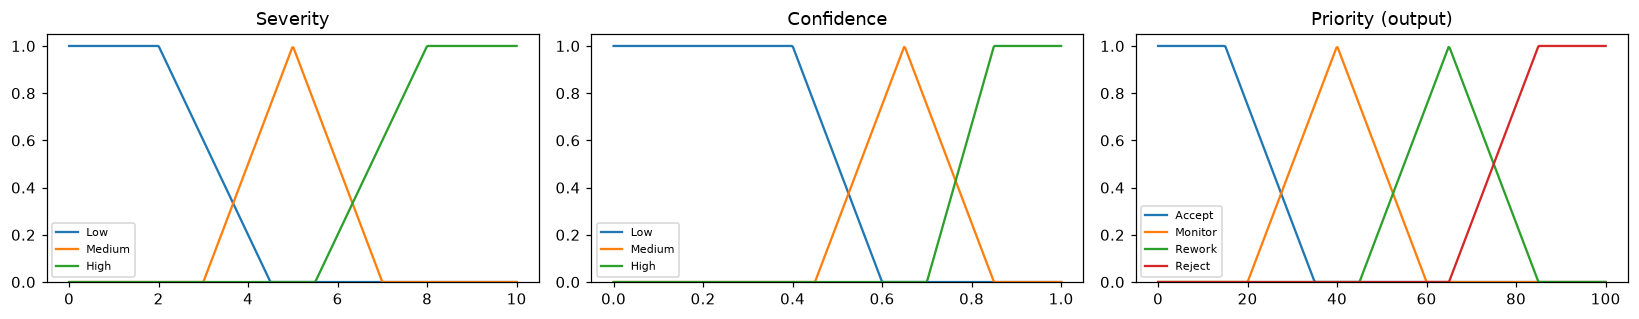

Severity per kelas (asumsi): {'Pastry': 4, 'Z_Scratch': 5, 'K_Scatch': 8, 'Stains': 2, 'Dirtiness': 1, 'Bumps': 6, 'Other_Faults': 5}


,severity,confidence,priority
0,Low,High,Accept
1,Low,Medium,Monitor
2,Low,Low,Monitor
3,Medium,High,Rework
4,Medium,Medium,Monitor
5,Medium,Low,Monitor
6,High,High,Reject
7,High,Medium,Rework
8,High,Low,Rework


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3))
for ax, (mfs, (lo, hi), judul) in zip(axes, [(FZ.SEV_MF, FZ.RANGES["severity"], "Severity"),
                                            (FZ.CONF_MF, FZ.RANGES["confidence"], "Confidence"),
                                            (FZ.OUT_MF, FZ.RANGES["priority"], "Priority (output)")]):
    u = np.linspace(lo, hi, 400)
    for k, v in mfs.items():
        ax.plot(u, FZ.mf(v, u), label=k)
    ax.set_title(judul); ax.set_ylim(0, 1.05); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()
print("Severity per kelas (asumsi):", C.SEVERITY)
pd.DataFrame(FZ.RULES, columns=["severity", "confidence", "priority"])

In [12]:
bd = best_models["D: GA + PSO + NN"]
results["E: GA + PSO + NN + Fuzzy"] = {**results["D: GA + PSO + NN"], "fuzzy": P.fuzzy_report(bd["proba"], S["y_te"])}
fz = results["E: GA + PSO + NN + Fuzzy"]["fuzzy"]
print("Distribusi keputusan pada test set:", fz["distribution"], "| rata-rata priority:", round(fz["mean_priority"], 2))
pd.DataFrame(fz["crosstab"]).T

Distribusi keputusan pada test set: {'Accept': 23, 'Monitor': 132, 'Rework': 156, 'Reject': 78} | rata-rata priority: 58.29


,Accept,Monitor,Rework,Reject
Pastry,0,29,3,0
Z_Scratch,0,4,34,0
K_Scatch,0,2,2,74
Stains,13,0,1,0
Dirtiness,7,3,1,0
Bumps,0,35,45,1
Other_Faults,3,59,70,3


In [13]:
# Contoh: 8 sampel test pertama, dari probabilitas MLP sampai keputusan fuzzy
rows = []
for i in range(8):
    o = FZ.decide(bd["proba"][i])
    rows.append({"aktual": C.CLASSES[S["y_te"][i]], "prediksi": C.CLASSES[int(bd["proba"][i].argmax())],
                 "confidence": round(o["confidence"], 3), "severity": round(o["severity"], 2),
                 "priority": round(o["priority"], 1), "keputusan": o["label"]})
pd.DataFrame(rows)

,aktual,prediksi,confidence,severity,priority,keputusan
0,Bumps,Bumps,0.945,5.95,69.3,Rework
1,K_Scatch,K_Scatch,1.000,8.00,86.9,Reject
2,Z_Scratch,Z_Scratch,0.992,5.00,65.0,Rework
3,Bumps,Bumps,0.520,4.91,40.0,Monitor
4,Stains,Stains,0.995,2.01,13.1,Accept
5,Other_Faults,Z_Scratch,0.868,5.00,65.0,Rework
6,Dirtiness,Dirtiness,0.939,1.26,13.1,Accept
7,Bumps,Bumps,0.775,5.75,56.3,Rework


## 7. Perbandingan model

,Model,n_fitur,Accuracy,Precision(macro),Recall(macro),F1(macro),F1(macro) std,Params
0,A: Baseline NN,27,0.7352,0.7263,0.7877,0.7471,0.0101,2183
1,B: GA + NN,16,0.7219,0.7046,0.7719,0.7299,0.0138,1831
2,C: PSO + NN,27,0.7445,0.7313,0.7813,0.7516,0.0119,12908
3,D: GA + PSO + NN,16,0.7470,0.7367,0.7929,0.7589,0.0042,12283
4,E: GA + PSO + NN + Fuzzy,16,0.7470,0.7367,0.7929,0.7589,0.0042,12283


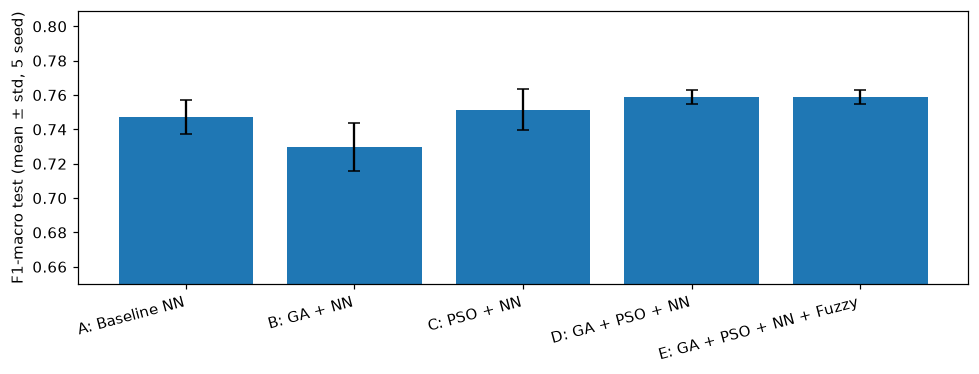

In [14]:
rows = [{"Model": k, "n_fitur": v["n_features"], "Accuracy": v["metrics"]["accuracy"]["mean"],
         "Precision(macro)": v["metrics"]["precision_macro"]["mean"], "Recall(macro)": v["metrics"]["recall_macro"]["mean"],
         "F1(macro)": v["metrics"]["f1_macro"]["mean"], "F1(macro) std": v["metrics"]["f1_macro"]["std"],
         "Params": v["n_params"]} for k, v in results.items()]
comparison = pd.DataFrame(rows)
display(comparison.round(4))
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.bar(comparison["Model"], comparison["F1(macro)"], yerr=comparison["F1(macro) std"], capsize=4, color="#1f77b4")
ax.set_ylim(comparison["F1(macro)"].min() - 0.08, min(1, comparison["F1(macro)"].max() + 0.05))
ax.set_ylabel("F1-macro test (mean ± std, 5 seed)"); plt.xticks(rotation=15, ha="right")
plt.tight_layout(); plt.show()

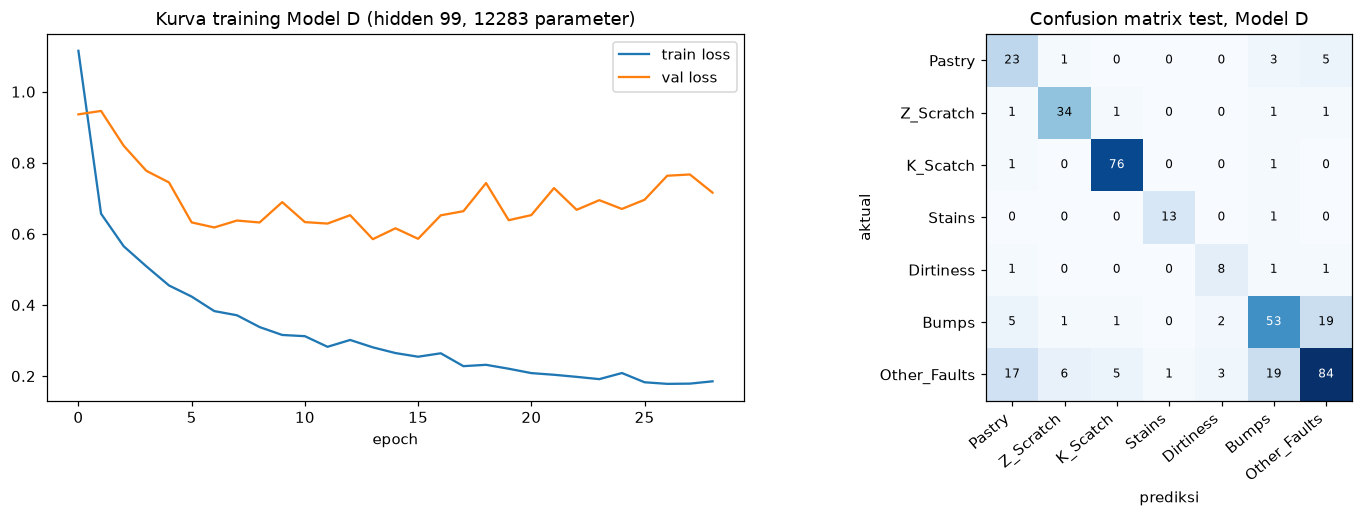

,precision,recall,f1-score,support
Pastry,0.479,0.719,0.575,32.0
Z_Scratch,0.810,0.895,0.850,38.0
K_Scatch,0.916,0.974,0.944,78.0
Stains,0.929,0.929,0.929,14.0
Dirtiness,0.615,0.727,0.667,11.0
Bumps,0.671,0.654,0.662,81.0
Other_Faults,0.764,0.622,0.686,135.0


In [15]:
r = results["D: GA + PSO + NN"]
cm = np.array(r["confusion_matrix"])
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
h = r["history"]
axes[0].plot(h["train_loss"], label="train loss"); axes[0].plot(h["val_loss"], label="val loss")
axes[0].set_title(f"Kurva training Model D (hidden {r['hp']['hidden']}, {r['n_params']} parameter)")
axes[0].set_xlabel("epoch"); axes[0].legend()
axes[1].imshow(cm, cmap="Blues")
for i in range(7):
    for j in range(7):
        axes[1].text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=8)
axes[1].set_xticks(range(7)); axes[1].set_xticklabels(C.CLASSES, rotation=40, ha="right")
axes[1].set_yticks(range(7)); axes[1].set_yticklabels(C.CLASSES)
axes[1].set_xlabel("prediksi"); axes[1].set_ylabel("aktual"); axes[1].set_title("Confusion matrix test, Model D")
plt.tight_layout(); plt.show()
pd.DataFrame(r["per_class"]).T.loc[C.CLASSES, ["precision", "recall", "f1-score", "support"]].round(3)

**Yang terlihat dari evaluasi test set**

| Model | F1-macro test | Selisih vs A |
|---|---|---|
| A: Baseline | 0.7471 ± 0.0101 | - |
| B: GA + NN | 0.7299 ± 0.0138 | −0.017 |
| C: PSO + NN | 0.7516 ± 0.0119 | +0.005 |
| D: GA + PSO + NN | **0.7589 ± 0.0042** | +0.012 |

- **Model D terbaik** di test set dan paling stabil antar-seed (std 0.0042, lebih kecil dari model lain). Selisihnya dengan baseline 0.012, kira-kira satu simpangan baku baseline, jadi keunggulannya ada tetapi kecil. Harganya, jumlah parameter naik dari 2.183 menjadi 12.283.
- **Model B justru di bawah baseline.** Subset fitur GA dipilih dengan hyperparameter default dan dinilai di data validation yang hanya 388 sampel, sehingga sebagian pilihannya cocok untuk validation tetapi tidak terbawa ke test. Pola serupa terlihat di PSO: F1 validation terbaik sekitar 0.81 sampai 0.82, tetapi F1 test model C dan D sekitar 0.75 sampai 0.76. Ini efek memilih "yang terbaik" dari banyak kandidat di data validation yang sama.
- Dari confusion matrix Model D, kelas yang paling mudah adalah K_Scatch (F1 0.944) dan Stains (0.929). Yang paling sulit adalah Pastry (0.575), Bumps (0.662), dan Other_Faults (0.686). Bumps dan Other_Faults saling tertukar 19 kali ke masing-masing arah, dan 17 Other_Faults ditebak Pastry. Other_Faults memang kelas "lain-lain" yang isinya campuran.
- Kurva training: val loss terendah sekitar epoch 13 sampai 15 lalu naik lagi, dan early stopping mengembalikan bobot terbaik sebelum model mulai overfit.
- **Fuzzy (Model E):** dari 389 sampel test, keputusannya 23 Accept, 132 Monitor, 156 Rework, dan 78 Reject. Pola keputusannya mengikuti severity: 74 dari 78 K_Scatch (severity 8) menjadi Reject, sedangkan Stains dan Dirtiness (severity 2 dan 1) kebanyakan Accept. Prediksi dengan confidence rendah turun ke Monitor (contoh: Bumps dengan confidence 0.52 di tabel contoh).

## 8. Simpan artefak untuk dashboard dan laporan

Format file sama persis dengan `train.py`: `model_final.npz`, `meta.json`, `ga.json`, `pso.json`, `results.json`, `test_pred.npz`, `comparison.csv`. Setelah sel ini, jalankan `streamlit run app.py` atau `python generate_report.py`.

In [16]:
C.ART.mkdir(exist_ok=True)
bd["m"].save(C.ART / "model_final.npz")
Xtr = S["X_tr"][ga_cols]
meta = {"classes": C.CLASSES, "all_features": all_cols, "selected_features": ga_cols,
        "scaler_mean": bd["sc"].mean_.tolist(), "scaler_scale": bd["sc"].scale_.tolist(),
        "hp_final": hp_d, "severity": C.SEVERITY,
        "feature_stats": {c: {"min": float(Xtr[c].min()), "max": float(Xtr[c].max()),
                              "median": float(Xtr[c].median())} for c in ga_cols},
        "split": {"train": len(S["y_sub"]), "val": len(S["y_val"]), "test": len(S["y_te"])},
        "synthetic": False, "quick": False, "runtime_sec": round(time.time() - t0, 1)}
json.dump(meta, open(C.ART / "meta.json", "w"), indent=1)
json.dump({"config": dict(C.GA), "runs": ga_runs, "stats": ga_stats, "all_features": all_cols, "selected": ga_cols,
           "best_chromosome": ga_best["chromosome"]}, open(C.ART / "ga.json", "w"), indent=1)
json.dump({"config": dict(C.PSO), "space": C.PSO_SPACE,
           "all_features": {"runs": pso_all, "stats": P.stats(pso_all)},
           "ga_features": {"runs": pso_ga, "stats": P.stats(pso_ga)}}, open(C.ART / "pso.json", "w"), indent=1)
json.dump(results, open(C.ART / "results.json", "w"), indent=1)
np.savez(C.ART / "test_pred.npz", proba=bd["proba"], y_true=S["y_te"])
comparison.to_csv(C.ART / "comparison.csv", index=False)
print(f"Total waktu notebook: {time.time() - t0:.0f} s")
print("Artefak:", sorted(p.name for p in C.ART.iterdir() if p.name != ".gitkeep"))

Total waktu notebook: 924 s
Artefak: ['comparison.csv', 'ga.json', 'meta.json', 'model_final.npz', 'pso.json', 'results.json', 'test_pred.npz']


Artefak sudah tersimpan. Langkah berikutnya:
- `streamlit run app.py` untuk membuka dashboard (perlu `pip install streamlit`).
- `python generate_report.py` untuk membuat `Laporan_Kelompok16.pdf` (perlu `pip install reportlab`). Bagian bertanda [ISI] di laporan tetap harus ditulis kelompok.